# Statistics and a simulated A/B test

Two parts:

1. **Describing the data honestly.** Order value and delivery time are skewed, so the mean alone misleads.
2. **Testing ideas.** Do late deliveries get worse reviews? Then a full A/B test workflow: sizing, randomization,
   sanity checks, analysis, business tradeoff, and why peeking is dangerous.

The A/B test is **simulated** on real Olist customer IDs. Order values and freight costs are real.

In [1]:
import hashlib

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_effectsize,
    proportions_ztest,
)

# The notebook runs from the notebooks/ folder, so the warehouse is one level up
con = duckdb.connect("../warehouse/insightops.duckdb", read_only=True)
orders = con.sql("select * from marts.fct_orders where is_valid_order").df()
print(orders.shape)

(98207, 26)


## 1. Mean vs median of order value

In [2]:
print(orders["order_value"].describe())
print("Mean:    ", round(orders["order_value"].mean(), 2))
print("Median:  ", round(orders["order_value"].median(), 2))
print("Skewness:", round(orders["order_value"].skew(), 2))

count    98207.000000
mean       160.228161
std        219.107014
min          0.000000
25%         61.960000
50%        105.280000
75%        176.715000
max      13664.080000
Name: order_value, dtype: float64
Mean:     160.23
Median:   105.28
Skewness: 9.26


The mean (R\$160) is about 50% above the median (R\$105), and skewness is above 9. A handful of orders
over R\$1,000 (the largest is R\$13,664) pull the mean up. The typical order is closer to R\$105.

**Decision:** the executive dashboard shows median order value next to AOV. AOV is still the right number
for revenue maths (revenue = orders x AOV); the median is the right number for "what does a normal order look like".

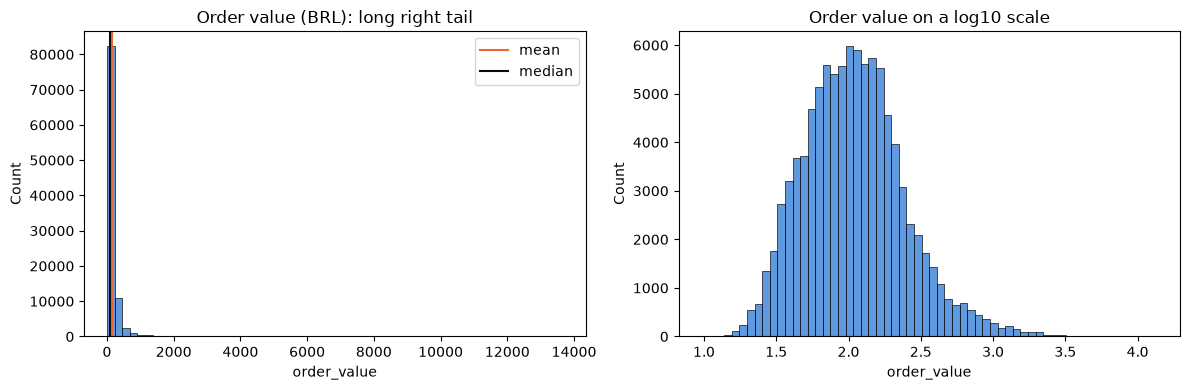

In [3]:
# A few valid orders have no items (order_value = 0), and log10(0) is undefined, so the log plot skips them
positive = orders.loc[orders["order_value"] > 0, "order_value"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(orders["order_value"], bins=60, ax=axes[0], color="#2a78d6")
axes[0].axvline(orders["order_value"].mean(), color="#eb6834", label="mean")
axes[0].axvline(orders["order_value"].median(), color="#0b0b0b", label="median")
axes[0].set_title("Order value (BRL): long right tail")
axes[0].legend()

sns.histplot(np.log10(positive), bins=60, ax=axes[1], color="#2a78d6")
axes[1].set_title("Order value on a log10 scale")

plt.tight_layout()
plt.show()

On the raw scale almost everything is squeezed into the first few bars. On a log scale the distribution
looks roughly bell-shaped, centered around 10^2 = R\$100. That's the signature of a log-normal-ish
variable: tests that assume normality should be run on the log, or replaced with rank-based tests.

### Delivery days: also skewed

count      96470.0
mean     12.496849
std       9.555071
min            0.0
25%            7.0
50%           10.0
75%           16.0
max          210.0
Name: delivery_days, dtype: Float64
Mean:     12.5
Median:   10.0
Skewness: 3.83


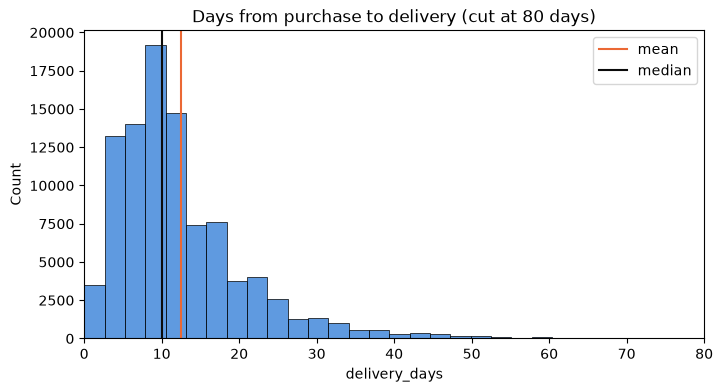

In [4]:
delivery = orders["delivery_days"].dropna()
print(delivery.describe())
print("Mean:    ", round(delivery.mean(), 2))
print("Median:  ", round(delivery.median(), 2))
print("Skewness:", round(delivery.skew(), 2))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(delivery, bins=80, ax=ax, color="#2a78d6")
ax.axvline(delivery.mean(), color="#eb6834", label="mean")
ax.axvline(delivery.median(), color="#0b0b0b", label="median")
ax.set_xlim(0, 80)
ax.set_title("Days from purchase to delivery (cut at 80 days)")
ax.legend()
plt.show()

Same story: the median is 10 days, the mean is higher, and a long tail of very slow deliveries stretches past
two months. The metric catalog reports delivery time as a **median** for this reason.

## 2. Do late deliveries get lower reviews?

In [5]:
delivered = orders[orders["is_delivered"] & orders["review_score"].notna()].copy()
late = delivered.loc[delivered["is_late"] == True, "review_score"]
on_time = delivered.loc[delivered["is_late"] == False, "review_score"]

print(f"Late orders:    n={len(late):,}  mean review={late.mean():.2f}")
print(f"On-time orders: n={len(on_time):,}  mean review={on_time.mean():.2f}")

# Review scores are ratings (1-5), not continuous numbers, so we use the
# Mann-Whitney U test, which compares groups without assuming a normal distribution.
u_stat, p_value = stats.mannwhitneyu(late, on_time, alternative="two-sided")
print(f"Mann-Whitney U p-value: {p_value:.4g}")

Late orders:    n=6,381  mean review=2.27
On-time orders: n=89,443  mean review=4.29
Mann-Whitney U p-value: 0


Late orders average about 2.3 stars against 4.3 for on-time orders, and the p-value is so small it underflows to 0.

**Significant, but not proof of cause.** This is observational data. Late orders differ from on-time orders in other
ways: they go more often to remote states, come from certain sellers, and are more often bulky items. Any of those
could also lower reviews. To claim causation we'd need an experiment, or at least to compare late and on-time
orders within the same state or seller. The next cell does the first of those.

In [6]:
# Does the gap survive inside a single state? Compare late vs on-time within each of the 10 biggest states.
top_states = delivered["customer_state"].value_counts().head(10).index
within_state = (
    delivered[delivered["customer_state"].isin(top_states)]
    .groupby(["customer_state", "is_late"])["review_score"].mean()
    .unstack()
    .rename(columns={False: "on_time", True: "late"})
)
within_state["gap"] = within_state["on_time"] - within_state["late"]
within_state.round(2).sort_values("gap")

is_late,on_time,late,gap
customer_state,,,
PR,4.3,2.68,1.63
ES,4.26,2.51,1.75
SP,4.32,2.55,1.78
BA,4.14,2.35,1.79
MG,4.28,2.36,1.92
SC,4.29,2.35,1.94
GO,4.24,2.2,2.03
RS,4.31,2.21,2.11
DF,4.26,1.97,2.29


The gap holds inside every one of the 10 largest states, at roughly 1.6 to 2.3 stars. So geography alone
doesn't explain it. It's still not causal proof (seller and category could matter too), but the size and
consistency of the gap make delivery reliability a strong candidate for investment.

## 3. A/B test: free shipping

**Scenario:** Olist tests free shipping. Half of customers see it (treatment), half don't (control).

- **Primary metric:** conversion, meaning the customer places an order during the test.
- **Baseline:** 5% (assumed).
- **Minimum effect worth detecting:** +10% relative, so 5.0% to 5.5%.

### 3.1 Sizing first

In [7]:
BASELINE_RATE = 0.05     # assumed conversion without free shipping
RELATIVE_LIFT = 0.10     # smallest lift worth detecting (10% relative)
target_rate = BASELINE_RATE * (1 + RELATIVE_LIFT)

effect_size = proportion_effectsize(target_rate, BASELINE_RATE)
n_per_group = NormalIndPower().solve_power(
    effect_size=effect_size,
    alpha=0.05,      # 5% false positive risk
    power=0.80,      # 80% chance to detect a real effect
    ratio=1.0,       # equal group sizes
    alternative="two-sided",
)
n_per_group = int(np.ceil(n_per_group))
print(f"Customers needed per group: {n_per_group:,}")

WEEKLY_ELIGIBLE_CUSTOMERS = 8000   # assumption: customers who can enter the test each week
weeks = int(np.ceil(2 * n_per_group / WEEKLY_ELIGIBLE_CUSTOMERS))
print(f"Test must run about {weeks} weeks")

Customers needed per group: 31,218
Test must run about 8 weeks


About 31,000 customers per group, roughly 8 weeks. Fixing the sample size **before** starting is what stops us
from ending the test the day results happen to look good (see section 3.7).

### 3.2 Randomize by customer

The unit of randomization is the **customer**, not the order. If orders were randomized, the same person could see
free shipping on one visit and not on the next, and their behavior would mix both versions. Hashing the customer ID
gives each person a stable group, and the salt makes each experiment's split independent of the last one.

In [8]:
customers = con.sql("select customer_unique_id from marts.dim_customers").df()

def assign_group(customer_id, salt="free_shipping_v1"):
    """Same customer always gets the same group. The salt makes each experiment's split different."""
    digest = hashlib.md5(f"{salt}:{customer_id}".encode()).hexdigest()
    return "treatment" if int(digest, 16) % 2 == 0 else "control"

customers["group"] = customers["customer_unique_id"].apply(assign_group)
print(customers["group"].value_counts())

group
treatment    48255
control      47841
Name: count, dtype: int64

### 3.3 Sample ratio mismatch (SRM) check

In [9]:
counts = customers["group"].value_counts()
chi2, srm_p = stats.chisquare([counts["control"], counts["treatment"]])
print(f"SRM check p-value: {srm_p:.3f}  (a value below 0.01 means the split is broken)")

SRM check p-value: 0.182  (a value below 0.01 means the split is broken)


48,255 vs 47,841 looks uneven, but with 96k customers a difference of 414 is well within chance (p = 0.18).
The split is fine.

### 3.4 Simulate the outcomes

This is the simulated part. The "true" rates are set here: 5.0% control, 5.6% treatment.

In [10]:
rng = np.random.default_rng(seed=42)   # a fixed seed makes results reproducible
TRUE_RATES = {"control": 0.050, "treatment": 0.056}

customers["converted"] = [rng.random() < TRUE_RATES[g] for g in customers["group"]]
summary = customers.groupby("group")["converted"].agg(["sum", "count", "mean"])
print(summary)

            sum  count      mean
group                           
control    2349  47841  0.049100
treatment  2783  48255  0.057673


### 3.5 Analyze: significance test and confidence interval

In [11]:
conv = summary.loc[["treatment", "control"], "sum"].values
n = summary.loc[["treatment", "control"], "count"].values

z_stat, p_value = proportions_ztest(conv, n)
low, high = confint_proportions_2indep(conv[0], n[0], conv[1], n[1], method="wald")
diff = conv[0] / n[0] - conv[1] / n[1]

print(f"Difference: {diff * 100:.2f} percentage points")
print(f"95% CI: [{low * 100:.2f}, {high * 100:.2f}] percentage points")
print(f"p-value: {p_value:.4f}")

Difference: 0.86 percentage points
95% CI: [0.57, 1.14] percentage points
p-value: 0.0000


Treatment converted at 5.77% vs 4.91% for control: +0.86 percentage points, 95% CI [+0.57, +1.14]. The interval
excludes 0, so the lift is statistically significant. The observed lift is a little above the true 0.6 pp we
simulated; that's ordinary sampling noise, and the true value sits just inside the interval.

### 3.6 A/A test

Split the control group in two with a different salt. Both halves saw the same thing, so there should be no
significant difference.

In [12]:
control = customers[customers["group"] == "control"].copy()
control["aa_group"] = control["customer_unique_id"].apply(lambda c: assign_group(c, salt="aa_check"))
aa = control.groupby("aa_group")["converted"].agg(["sum", "count"])
_, aa_p = proportions_ztest(aa["sum"].values, aa["count"].values)
print(f"A/A test p-value: {aa_p:.3f}  (should usually be above 0.05)")

A/A test p-value: 0.399  (should usually be above 0.05)


p = 0.40: no difference, as expected. The setup isn't manufacturing effects.

### 3.7 The business tradeoff

Significant isn't the same as worth doing. Free shipping costs money on **every** treatment order, not just the
extra ones. Real Olist numbers for order value and freight:

In [13]:
typical_order_value = orders["order_value"].median()
avg_freight = orders["freight_value"].mean()

treated_customers = n[0]
extra_orders = diff * treated_customers
extra_revenue = extra_orders * typical_order_value
shipping_cost = conv[0] * avg_freight   # every treatment order now ships free

print(f"Extra orders:        {extra_orders:,.0f}")
print(f"Extra revenue:       R${extra_revenue:,.0f}")
print(f"Free shipping cost:  R${shipping_cost:,.0f}")

Extra orders:        414
Extra revenue:       R$43,551
Free shipping cost:  R$63,509


In [14]:
# Olist earns a commission on sales, not the full order value.
COMMISSION_RATE = 0.10   # assumption
extra_commission = extra_revenue * COMMISSION_RATE
print(f"Extra commission at {COMMISSION_RATE:.0%}: R${extra_commission:,.0f}")
print(f"Net effect:               R${extra_commission - shipping_cost:,.0f}")

# How big would the lift need to be just to break even?
breakeven_extra_orders = shipping_cost / (typical_order_value * COMMISSION_RATE)
print(f"Break-even needs about {breakeven_extra_orders:,.0f} extra orders, "
      f"a lift of {100 * breakeven_extra_orders / treated_customers:.1f} pp on {treated_customers:,} customers")

Extra commission at 10%: R$4,355
Net effect:               R$-59,154
Break-even needs about 6,032 extra orders, a lift of 12.5 pp on 48,255 customers


Even taking the full extra revenue, the R\$63.5k shipping bill is bigger than the R\$43.6k gained. At a 10% commission
Olist keeps only about R\$4.4k of that revenue, so the net effect is about **-R\$59k**. Breaking even would take a lift of
roughly 12.5 pp, more than tripling conversion. That's not a realistic outcome for free shipping.

**Decision: don't ship blanket free shipping.** The test shows customers respond to it, which makes a narrower version
worth testing: free shipping only above a basket threshold, so the cost applies to large orders where the commission
can cover it.

### 3.8 Why you must not "peek"

500 A/A tests (no real effect), checking the p-value every day for 20 days and stopping at the first p < 0.05:

In [15]:
def peeking_false_positive_rate(n_experiments=500, n_per_day=200, days=20, rate=0.05):
    rng = np.random.default_rng(7)
    false_positives = 0
    for _ in range(n_experiments):
        a = rng.random((days, n_per_day)) < rate
        b = rng.random((days, n_per_day)) < rate
        for day in range(1, days + 1):
            conv_ab = [a[:day].sum(), b[:day].sum()]
            n_ab = [day * n_per_day, day * n_per_day]
            if min(conv_ab) == 0:
                continue
            if proportions_ztest(conv_ab, n_ab)[1] < 0.05:
                false_positives += 1
                break
    return false_positives / n_experiments

print(f"False positive rate with daily peeking: {peeking_false_positive_rate():.0%} (should be 5%)")

False positive rate with daily peeking: 24% (should be 5%)


24% instead of 5%. Checking daily and stopping on the first good-looking p-value nearly **five times** the false
positive rate. That's why the sample size was fixed in 3.1 and the analysis runs once, at the end.